In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
rng = np.random.default_rng()

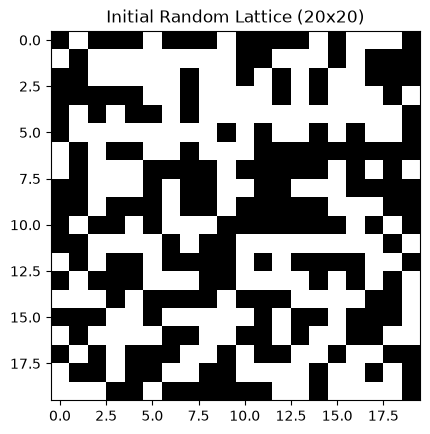

In [2]:
def initialise_grid(N):
    return np.random.choice([-1, 1], size=(N, N))

# Define grid size and test the visualization
N = 20
grid = initialise_grid(N)

plt.imshow(grid, cmap='grey')
plt.title(f"Initial Random Lattice ({N}x{N})")
plt.show()

In [3]:
def energy_local(grid, x, y, J=1.0):
    N = grid.shape[0]
    spin = grid [x, y] #pulls value of spin at coordinate (x,y)

    #finding value of spin at 4 nearest neighbours
    up_neighbour = grid[(x-1) % N, y]
    down_neighbour = grid[(x+1) % N, y]
    left_neighbour = grid[x, (y-1) % N]
    right_neighbour = grid[x, (y+1) % N]

    #summing the values of spin of 4 nearest neighbours
    neighbour_sum = up_neighbour + down_neighbour + left_neighbour + right_neighbour

    #calculates local energy at (x,y)
    local_energy = -1*J*spin*neighbour_sum
    return local_energy

In [4]:
def total_magnetisation(grid):
    return np.sum(grid)

In [5]:
def total_energy(grid):
    total = 0
    N=grid.shape[0]
    for n in range(N):
        for m in range(N):
            total += energy_local(grid, n, m, J=1.0)
    return total/2

In [6]:
T_values = np.linspace(1.0,3.5, 100)
final_magnetisation=[]
final_energy=[]
for T in T_values:
    for j in range(0,5000): # run 1000 times to reach equilibrium
        for i in range(0, N**2): #perform 1 monte carlo sweep
            coordinate=rng.integers(0,N,size=2) #generate a random coordinate
            current_energy=energy_local(grid, coordinate[0], coordinate[1], J=1.0) #find current energy
            delta_E=-2*current_energy #calculate change in energy
            if delta_E<=0:
                grid[coordinate[0], coordinate[1]] *= -1 #always allow flips that decrease the total energy
            elif delta_E>0:
                P=np.exp(-delta_E/T) #calculate probability of allowing flip
                r = np.random.random_sample()
                if r<P:
                    grid[coordinate[0], coordinate[1]] *= -1
    magnetisation_list = []
    energy_list = []
    for j in range(0,5000):
        for i in range(0, N**2): #perform 1 monte carlo sweep
            coordinate=rng.integers(0,N,size=2) #generate a random coordinate
            current_energy=energy_local(grid, coordinate[0], coordinate[1], J=1.0) #find current energy
            delta_E=-2*current_energy #calculate change in energy
            if delta_E<=0:
                grid[coordinate[0], coordinate[1]] *= -1 #always allow flips that decrease the total energy
            elif delta_E>0:
                P=np.exp(-delta_E/T) #calculate probability of allowing flip
                r = np.random.random_sample()
                if r<P:
                    grid[coordinate[0], coordinate[1]] *= -1
        magnetisation_list.append(total_magnetisation(grid))
        energy_list.append(total_energy(grid))
    av_magnet = np.mean(np.abs(magnetisation_list))
    av_energy = np.mean(energy_list)
    final_magnetisation.append(av_magnet)
    final_energy.append(av_energy)
    print(f"Finished computing T = {T:.2f}")

print("done")

Finished computing T = 1.00
Finished computing T = 1.03
Finished computing T = 1.05
Finished computing T = 1.08
Finished computing T = 1.10
Finished computing T = 1.13
Finished computing T = 1.15
Finished computing T = 1.18
Finished computing T = 1.28
Finished computing T = 1.30
Finished computing T = 1.33
Finished computing T = 1.35
Finished computing T = 1.38
Finished computing T = 1.40
Finished computing T = 1.43
Finished computing T = 1.45
Finished computing T = 1.48
Finished computing T = 1.53
Finished computing T = 1.56
Finished computing T = 1.58
Finished computing T = 1.61
Finished computing T = 1.63
Finished computing T = 1.66
Finished computing T = 1.68
Finished computing T = 1.71
Finished computing T = 1.73
Finished computing T = 1.76
Finished computing T = 1.78
Finished computing T = 1.81
Finished computing T = 1.83
Finished computing T = 1.93
Finished computing T = 1.96
Finished computing T = 1.98
Finished computing T = 2.01
Finished computing T = 2.04
Finished computing T

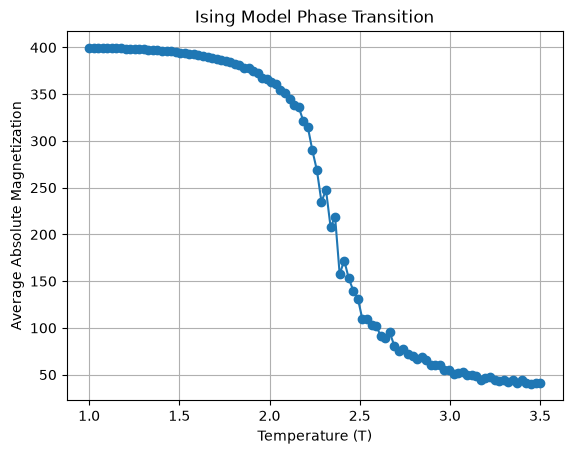

In [7]:
plt.plot(T_values, final_magnetisation, marker='o')
plt.xlabel('Temperature (T)')
plt.ylabel('Average Absolute Magnetization')
plt.title('Ising Model Phase Transition')
plt.grid(True)
plt.show()

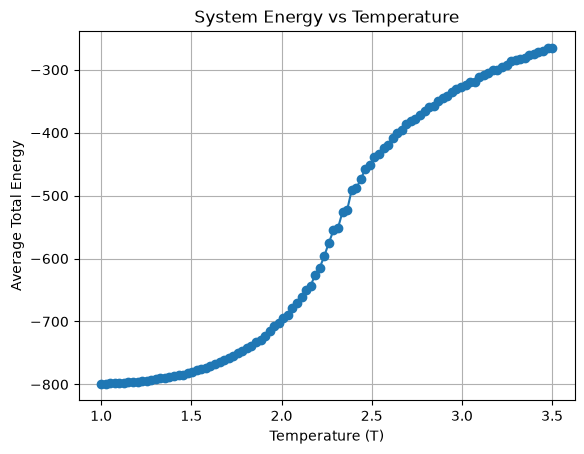

In [8]:
plt.plot(T_values, final_energy, marker='o')
plt.xlabel('Temperature (T)')
plt.ylabel('Average Total Energy')
plt.title('System Energy vs Temperature')
plt.grid(True)
plt.show()